# Step 2: Solve a 1D Poisson equation (elliptic PDE) with a PINN

**Problem** ($x \in (0,1)$)

$$-u''(x) = \pi^2 \sin(\pi x), \qquad u(0)=u(1)=0$$

**Exact solution:** $u(x) = \sin(\pi x)$

---

## Differences from the previous notebook

- **Second derivative** $u''$ is needed → apply `grad` **twice**  
- **Two** boundary points (Dirichlet)  
- Finally compare errors with **finite differences (FD)** (basic verification)

Loss: $\mathcal{L} = \mathcal{L}_{\mathrm{PDE}} + \lambda_{\mathrm{BC}} \mathcal{L}_{\mathrm{BC}}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)

class MLP(nn.Module):
    def __init__(self, d_in=1, d_out=1, width=64, depth=5):
        super().__init__()
        layers = [nn.Linear(d_in, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.Tanh()]
        layers.append(nn.Linear(width, d_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def grad(y, x):
    return torch.autograd.grad(
        y, x,
        grad_outputs=torch.ones_like(y),
        create_graph=True,
        retain_graph=True,
    )[0]

def relative_l2(pred, ref):
    return np.linalg.norm(pred - ref) / (np.linalg.norm(ref) + 1e-12)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

PI = np.pi
X_MIN, X_MAX = 0.0, 1.0

device: cpu


## Reference solution, source term, and finite differences (classical solver)

In [2]:
def exact_u(x):
    return np.sin(PI * x)

def source(x):
    """f(x) in -u'' = f  =>  f = pi^2 sin(pi x)"""
    return (PI ** 2) * torch.sin(PI * x)

def finite_difference_poisson(n=101):
    """Second-order FD for -u'' = pi^2 sin(pi x), u(0)=u(1)=0"""
    x = np.linspace(X_MIN, X_MAX, n)
    h = x[1] - x[0]
    main = 2.0 / h ** 2
    off = -1.0 / h ** 2
    A = np.zeros((n - 2, n - 2))
    np.fill_diagonal(A, main)
    np.fill_diagonal(A[1:], off)
    np.fill_diagonal(A[:, 1:], off)
    f = (PI ** 2) * np.sin(PI * x[1:-1])
    u_inner = np.linalg.solve(A, f)
    u = np.zeros(n)
    u[1:-1] = u_inner
    return x, u

x_fd, u_fd = finite_difference_poisson()
err_fd = relative_l2(u_fd, exact_u(x_fd))
print(f"FD relative L2 error vs exact: {err_fd:.4e}")

FD relative L2 error vs exact: 8.2251e-05


## PINN training

Residual: $\text{res} = -u'' - f(x)$ (to satisfy $-u'' = f$)

In [7]:
N_COLLOC = 256
EPOCHS = 20000
LR = 1e-4
W_BC = 200.0

model = MLP().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

x_int = torch.linspace(X_MIN + 1e-3, X_MAX - 1e-3, N_COLLOC, device=device).view(-1, 1)
x_int.requires_grad_(True)
x_bc = torch.tensor([[X_MIN], [X_MAX]], device=device, dtype=torch.float32)
u_bc_target = torch.zeros(2, 1, device=device)

history = []
for epoch in range(EPOCHS):
    optimizer.zero_grad()

    u_int = model(x_int)
    du_dx = grad(u_int, x_int)
    d2u_dx2 = grad(du_dx, x_int)
    res = -d2u_dx2 - source(x_int)
    loss_pde = torch.mean(res ** 2)

    u_bc = model(x_bc)
    loss_bc = torch.mean((u_bc - u_bc_target) ** 2)

    loss = loss_pde + W_BC * loss_bc
    loss.backward()
    optimizer.step()
    history.append(loss.item())

    if (epoch + 1) % 2000 == 0:
        print(
            f"epoch {epoch+1:5d}  loss={loss.item():.3e}  "
            f"pde={loss_pde.item():.3e}  bc={loss_bc.item():.3e}"
        )

epoch  2000  loss=2.979e-03  pde=2.979e-03  bc=6.892e-11
epoch  4000  loss=2.769e-03  pde=2.704e-03  bc=3.250e-07
epoch  6000  loss=2.537e-03  pde=2.535e-03  bc=8.606e-09
epoch  8000  loss=4.207e-03  pde=2.395e-03  bc=9.057e-06
epoch 10000  loss=2.603e-03  pde=2.242e-03  bc=1.808e-06
epoch 12000  loss=2.103e-03  pde=2.085e-03  bc=9.036e-08
epoch 14000  loss=1.934e-03  pde=1.912e-03  bc=1.107e-07
epoch 16000  loss=1.685e-03  pde=1.683e-03  bc=5.971e-09
epoch 18000  loss=1.780e-03  pde=1.340e-03  bc=2.201e-06
epoch 20000  loss=9.956e-04  pde=7.695e-04  bc=1.131e-06


## PINN vs exact solution vs finite differences

relative L2 error  PINN: 1.1320e-03
relative L2 error  FD:   3.3302e-05


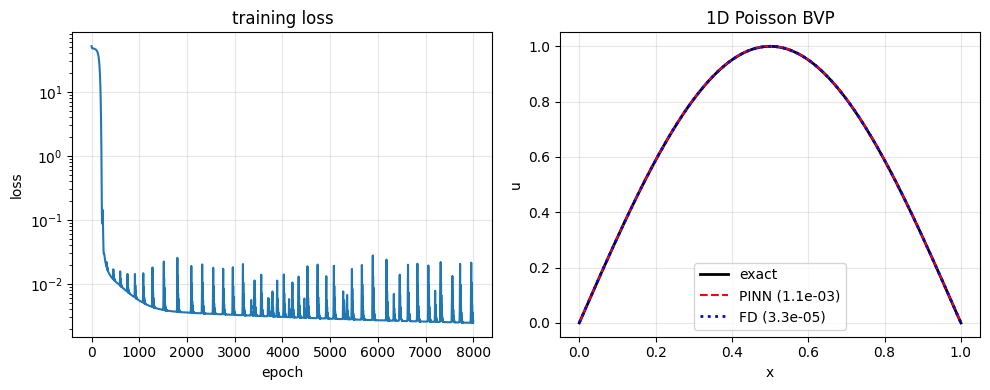

In [6]:
x_test = np.linspace(X_MIN, X_MAX, 400)
x_t = torch.tensor(x_test, dtype=torch.float32, device=device).view(-1, 1)
with torch.no_grad():
    u_pinn = model(x_t).cpu().numpy().ravel()
u_exact = exact_u(x_test)
u_fd_interp = np.interp(x_test, x_fd, u_fd)

err_pinn = relative_l2(u_pinn, u_exact)
err_fd_test = relative_l2(u_fd_interp, u_exact)
print(f"relative L2 error  PINN: {err_pinn:.4e}")
print(f"relative L2 error  FD:   {err_fd_test:.4e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].semilogy(history)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_title("training loss")
axes[0].grid(True, alpha=0.3)

axes[1].plot(x_test, u_exact, "k-", lw=2, label="exact")
axes[1].plot(x_test, u_pinn, "r--", lw=1.5, label=f"PINN ({err_pinn:.1e})")
axes[1].plot(x_fd, u_fd, "b:", lw=2, label=f"FD ({err_fd_test:.1e})")
axes[1].set_xlabel("x")
axes[1].set_ylabel("u")
axes[1].set_title("1D Poisson BVP")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Summary and next steps

| Method | Role |
|------|------|
| Exact solution | **Verification reference** (gold standard) |
| FD | Classical numerical solution (compare with PINN) |
| PINN | Learn from PDE residual + boundary conditions |

**Next:** Apply the same pipeline to your research problem (an equation with a known reference solution).  
Varying `W_BC` and network width to study sensitivity is also useful.